# Modul


## MLP Klasifikasi

In [180]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from imblearn.metrics import sensitivity_specificity_support
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder
from sklearn.neural_network import MLPClassifier

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [181]:
df = pd.read_csv("https://raw.githubusercontent.com/FauzanTrisuladana/content/refs/heads/master/BankChurners.csv")
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


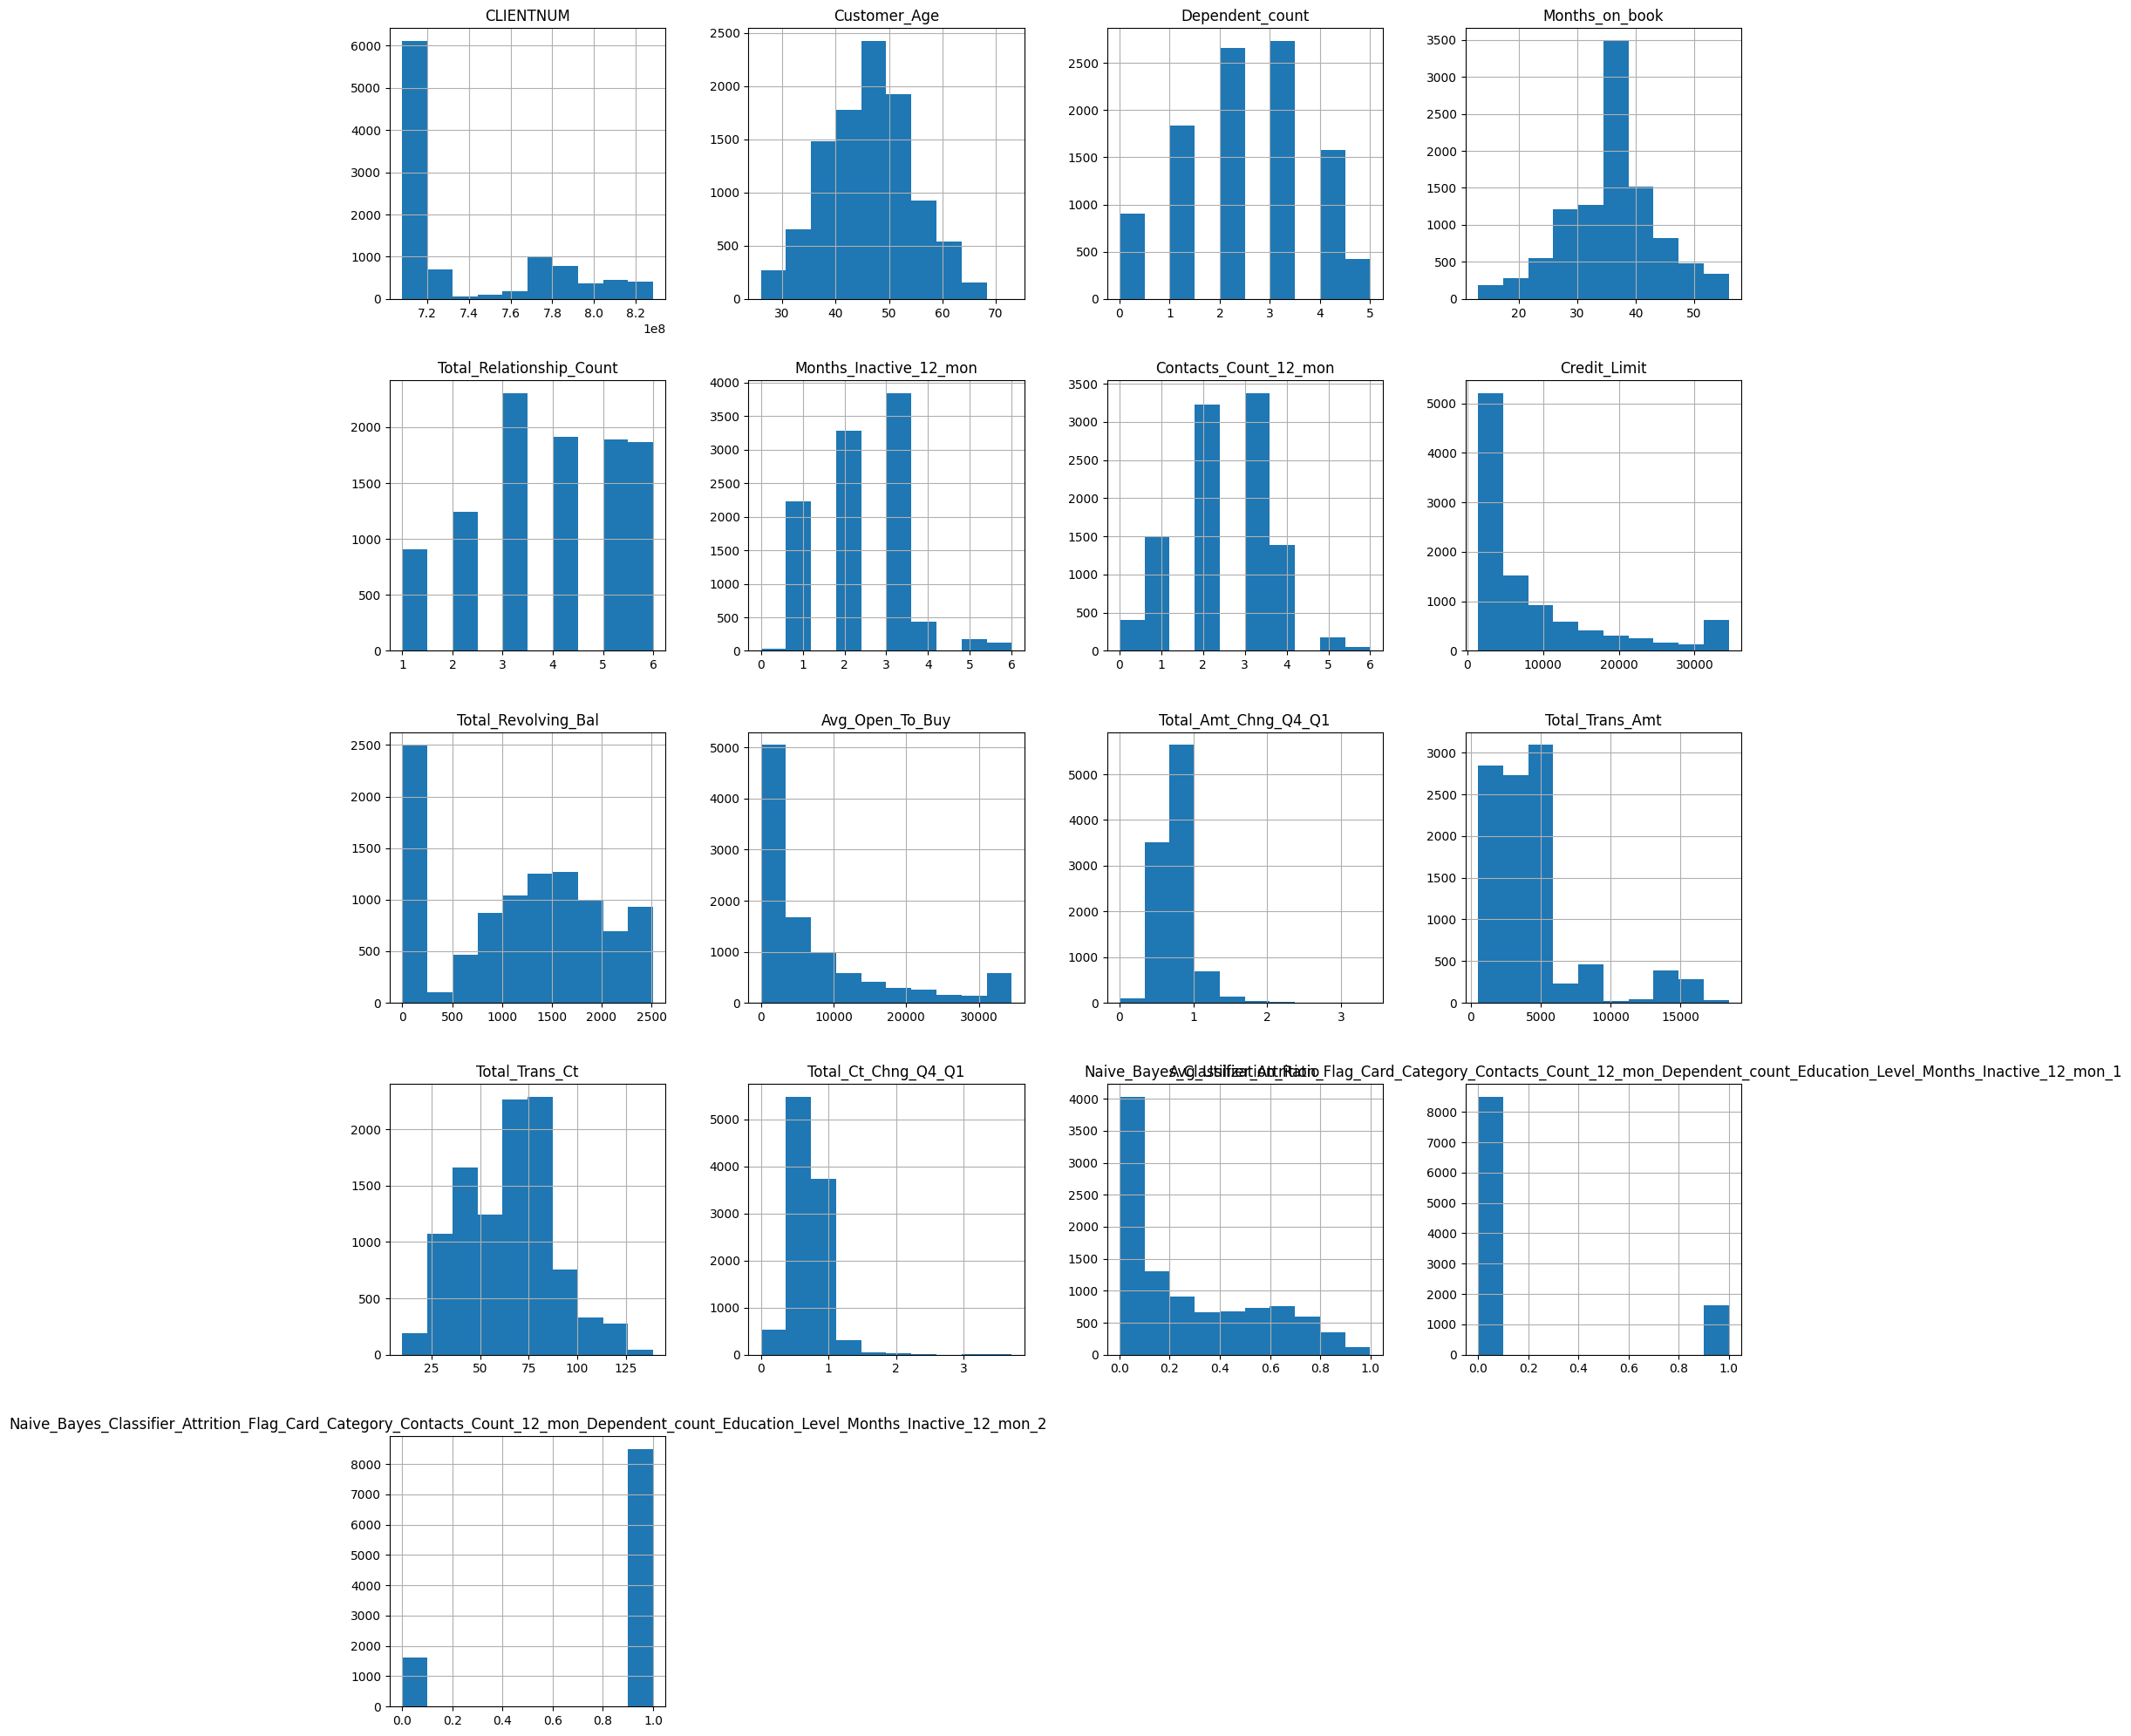

In [182]:
df.hist(figsize=(20,25))
plt.show()

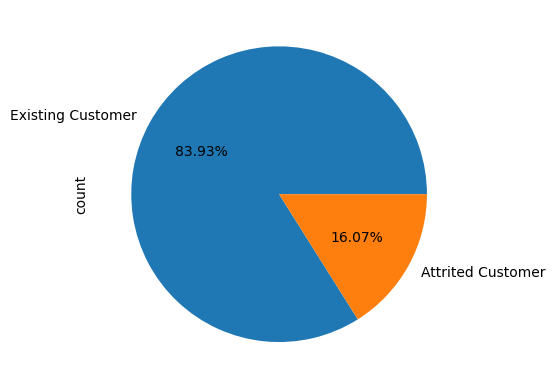

In [183]:
# cek persentase target class
data = df['Attrition_Flag'].value_counts()
data.plot(kind='pie', autopct='%.2f%%')
plt.show()

In [184]:
df.isnull().sum()

,0
CLIENTNUM,0
Attrition_Flag,0
Customer_Age,0
Gender,0
Dependent_count,0
Education_Level,0
Marital_Status,0
Income_Category,0
Card_Category,0
Months_on_book,0


In [185]:
# cek kategorikal atribut
df_X = df.drop(columns=['CLIENTNUM', 'Attrition_Flag'], axis=1)
df_y = df['Attrition_Flag']
cats = df_X.select_dtypes(include=['object', 'bool']).columns
print(cats)

Index(['Gender', 'Education_Level', 'Marital_Status', 'Income_Category',
       'Card_Category'],
      dtype='object')


In [186]:
# get X and y
df_X = df.drop(['CLIENTNUM', 'Attrition_Flag'], axis=1)
df_y = df[['Attrition_Flag']]

# label encoding for y.
# merubah nilai yg ada di y menjadi 0 atau 1.
# sebenarnya ini tidak diperlukan karena nilai y di dataset sudah 0 atau 1
le = LabelEncoder()
df_y = le.fit_transform(df_y['Attrition_Flag'])

# categorical encoding
# merubah categorical value menjadi numerical value
# bisa pakai label encoding, ordinal atau one hot encoding
cats = df_X.select_dtypes(include=['object', 'bool']).columns
cat_features = list(cats.values)
le = LabelEncoder()
for i in cat_features:
    le.fit(df_X[i])
    df_X[i] = le.transform(df_X[i])

# menyimpan X dan y menjadi numpy arrays
X = df_X.astype(float).values
y = df_y.astype(float)

# hold-out method, dibagi menjadi training dan testing set. 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# scaling
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

# mulai learning
model = MLPClassifier(max_iter=500)

# model=MLPClassifier(max_iter=1000, random_state=42, activation='logistic')
model.fit(X_train, y_train)

MLPClassifier(max_iter=500)

In [187]:
df_X

,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,45,1,3,3,1,2,0,39,5,1,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.999910
1,49,0,5,2,2,4,0,44,6,1,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.999940
2,51,1,3,2,1,3,0,36,4,1,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.999980
3,40,0,4,3,3,4,0,34,3,4,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.999870
4,40,1,3,5,1,2,0,21,5,1,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.999980
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,50,1,2,2,2,1,0,40,3,2,...,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462,0.000191,0.999810
10123,41,1,2,6,0,1,0,25,4,2,...,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511,0.995270,0.004729
10124,44,0,1,3,1,4,0,36,5,3,...,5409.0,0,5409.0,0.819,10291,60,0.818,0.000,0.997880,0.002118
10125,30,1,2,2,3,1,0,36,4,3,...,5281.0,0,5281.0,0.535,8395,62,0.722,0.000,0.996710,0.003294


In [188]:
X_train[0]

array([ 0.33519339,  1.05692234, -0.25437357,  0.4990858 , -0.61710507,
       -0.56580813, -0.25591165,  0.25586758, -0.51407227, -0.33752656,
       -2.22835505, -0.05917368,  0.98686487, -0.14826286, -0.57038549,
       -0.90317904, -1.65490765, -1.12681489, -0.11093226, -0.43609419,
        0.43609247])

Accuracy  1.0
Precision  1.0
Recall  1.0
Confusion matrix  [[ 496    0]
 [   0 2543]]


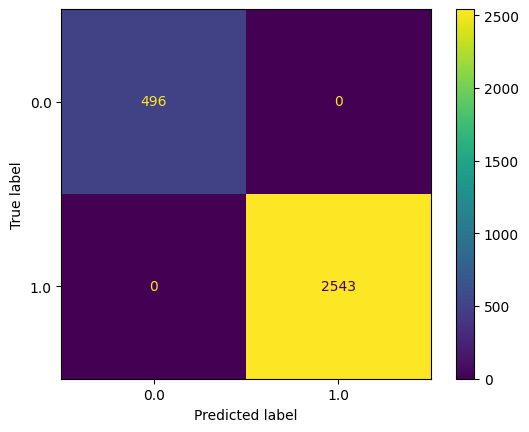

In [189]:
# visualisasi

y_pred = model.predict(X_test)
print('Accuracy ', accuracy_score(y_test, y_pred))
print('Precision ', precision_score(y_test, y_pred))
print('Recall ', recall_score(y_test, y_pred))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred), display_labels=model.classes_)
disp.plot()
plt.show()

In [190]:
data = [{'Customer_Age':68, 'Gender':'F', 'Dependent_count':5, 'Education_Level':'Graduate',
         'Marital_Status':'Single', 'Income_Category':'Less than $40K', 'Card_Category':'Blue',
         'Months_on_book':44, 'Total_Relationship_Count':6, 'Months_Inactive_12_mon':1,
         'Contacts_Count_12_mon':2, 'Credit_Limit':8700, 'Total_Revolving_Bal':800, 'Avg_Open_To_Buy':7392,
         'Total_Amt_Chng_Q4_Q1':1.541, 'Total_Trans_Amt':1200, 'Total_Trans_Ct':33, 'Total_Ct_Chng_Q4_Q1':3.714,
         'Avg_Utilization_Ratio':0.10},
        {'Customer_Age':50, 'Gender':'M', 'Dependent_count':2, 'Education_Level':'Graduate',
         'Marital_Status':'Single', 'Income_Category':'$40K - $60K', 'Card_Category':'Blue',
         'Months_on_book':38, 'Total_Relationship_Count':3, 'Months_Inactive_12_mon':2,
         'Contacts_Count_12_mon':0, 'Credit_Limit':8077.0, 'Total_Revolving_Bal':1965, 'Avg_Open_To_Buy':6112.0,
         'Total_Amt_Chng_Q4_Q1':0.637, 'Total_Trans_Amt':1329, 'Total_Trans_Ct':26, 'Total_Ct_Chng_Q4_Q1':0.444,
         'Avg_Utilization_Ratio':0.243}]

df_input = pd.DataFrame(data)

# categorical encoding
# Use the original df_X columns to ensure correct feature order and presence
original_cols = df.drop(['CLIENTNUM', 'Attrition_Flag'], axis=1).columns
df_input = df_input.reindex(columns=original_cols, fill_value=0) # Reindex to match original columns, fill missing with 0 if necessary

cats = df_input.select_dtypes(include=['object', 'bool']).columns
cat_features = list(cats.values)

# Create a dictionary to store the fitted LabelEncoders for each categorical feature
label_encoders = {}

for i in cat_features:
    # Initialize a new LabelEncoder for each feature
    le = LabelEncoder()
    all_unique_values = pd.concat([df_X[i], df_input[i]]).astype(str).unique()
    le.fit(all_unique_values)
    label_encoders[i] = le
    df_input[i] = label_encoders[i].transform(df_input[i].astype(str))

# scaling
df_input = scaler.transform(df_input.astype(float).values)

result = model.predict(df_input)
for i in result:
    int_result = int(i)
    if (int_result == 0):
        decision = 'Existing Customer'
    elif (int_result == 1):
        decision = 'Attrited Customer'
    else:
        decision = 'Not defined'
    print('Result prediction is ', decision)

Result prediction is  Attrited Customer
Result prediction is  Attrited Customer


In [191]:
df_input

array([[ 2.69329634e+00,  3.05998799e+00,  2.08111844e+00,
         2.13632131e+00,  3.46696655e+00,  2.75905345e+00,
         5.59066952e+00,  1.00082113e+00,  1.41213614e+00,
        -1.32245379e+00, -4.09541072e-01,  9.83216719e-03,
        -4.44011649e-01, -6.39776613e-03,  3.62111505e+00,
        -9.40555602e-01, -1.35950899e+00,  1.26325766e+01,
        -6.32215193e-01, -4.36229815e-01, -2.30899076e+00],
       [ 4.59304076e-01,  5.06305363e+00, -2.54373565e-01,
         2.13632131e+00,  3.46696655e+00, -1.89575277e+00,
         5.59066952e+00,  2.55867580e-01, -5.14072268e-01,
        -3.37526559e-01, -2.22835505e+00, -5.91736804e-02,
         9.86864872e-01, -1.48262862e-01, -5.70385493e-01,
        -9.03179036e-01, -1.65490765e+00, -1.12681489e+00,
        -1.10932261e-01, -4.36229815e-01, -2.30899076e+00]])

In [192]:
cat_features

['Gender',
 'Education_Level',
 'Marital_Status',
 'Income_Category',
 'Card_Category']

In [193]:
result

array([1., 1.])

## MPL Regresi

In [194]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [195]:
df = pd.read_csv("https://raw.githubusercontent.com/FauzanTrisuladana/content/refs/heads/master/kc_house_data.csv")
df.head()


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180.0,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170.0,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770.0,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050.0,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680.0,0,1987,0,98074,47.6168,-122.045,1800,7503


In [196]:
df.isnull().sum()

,0
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


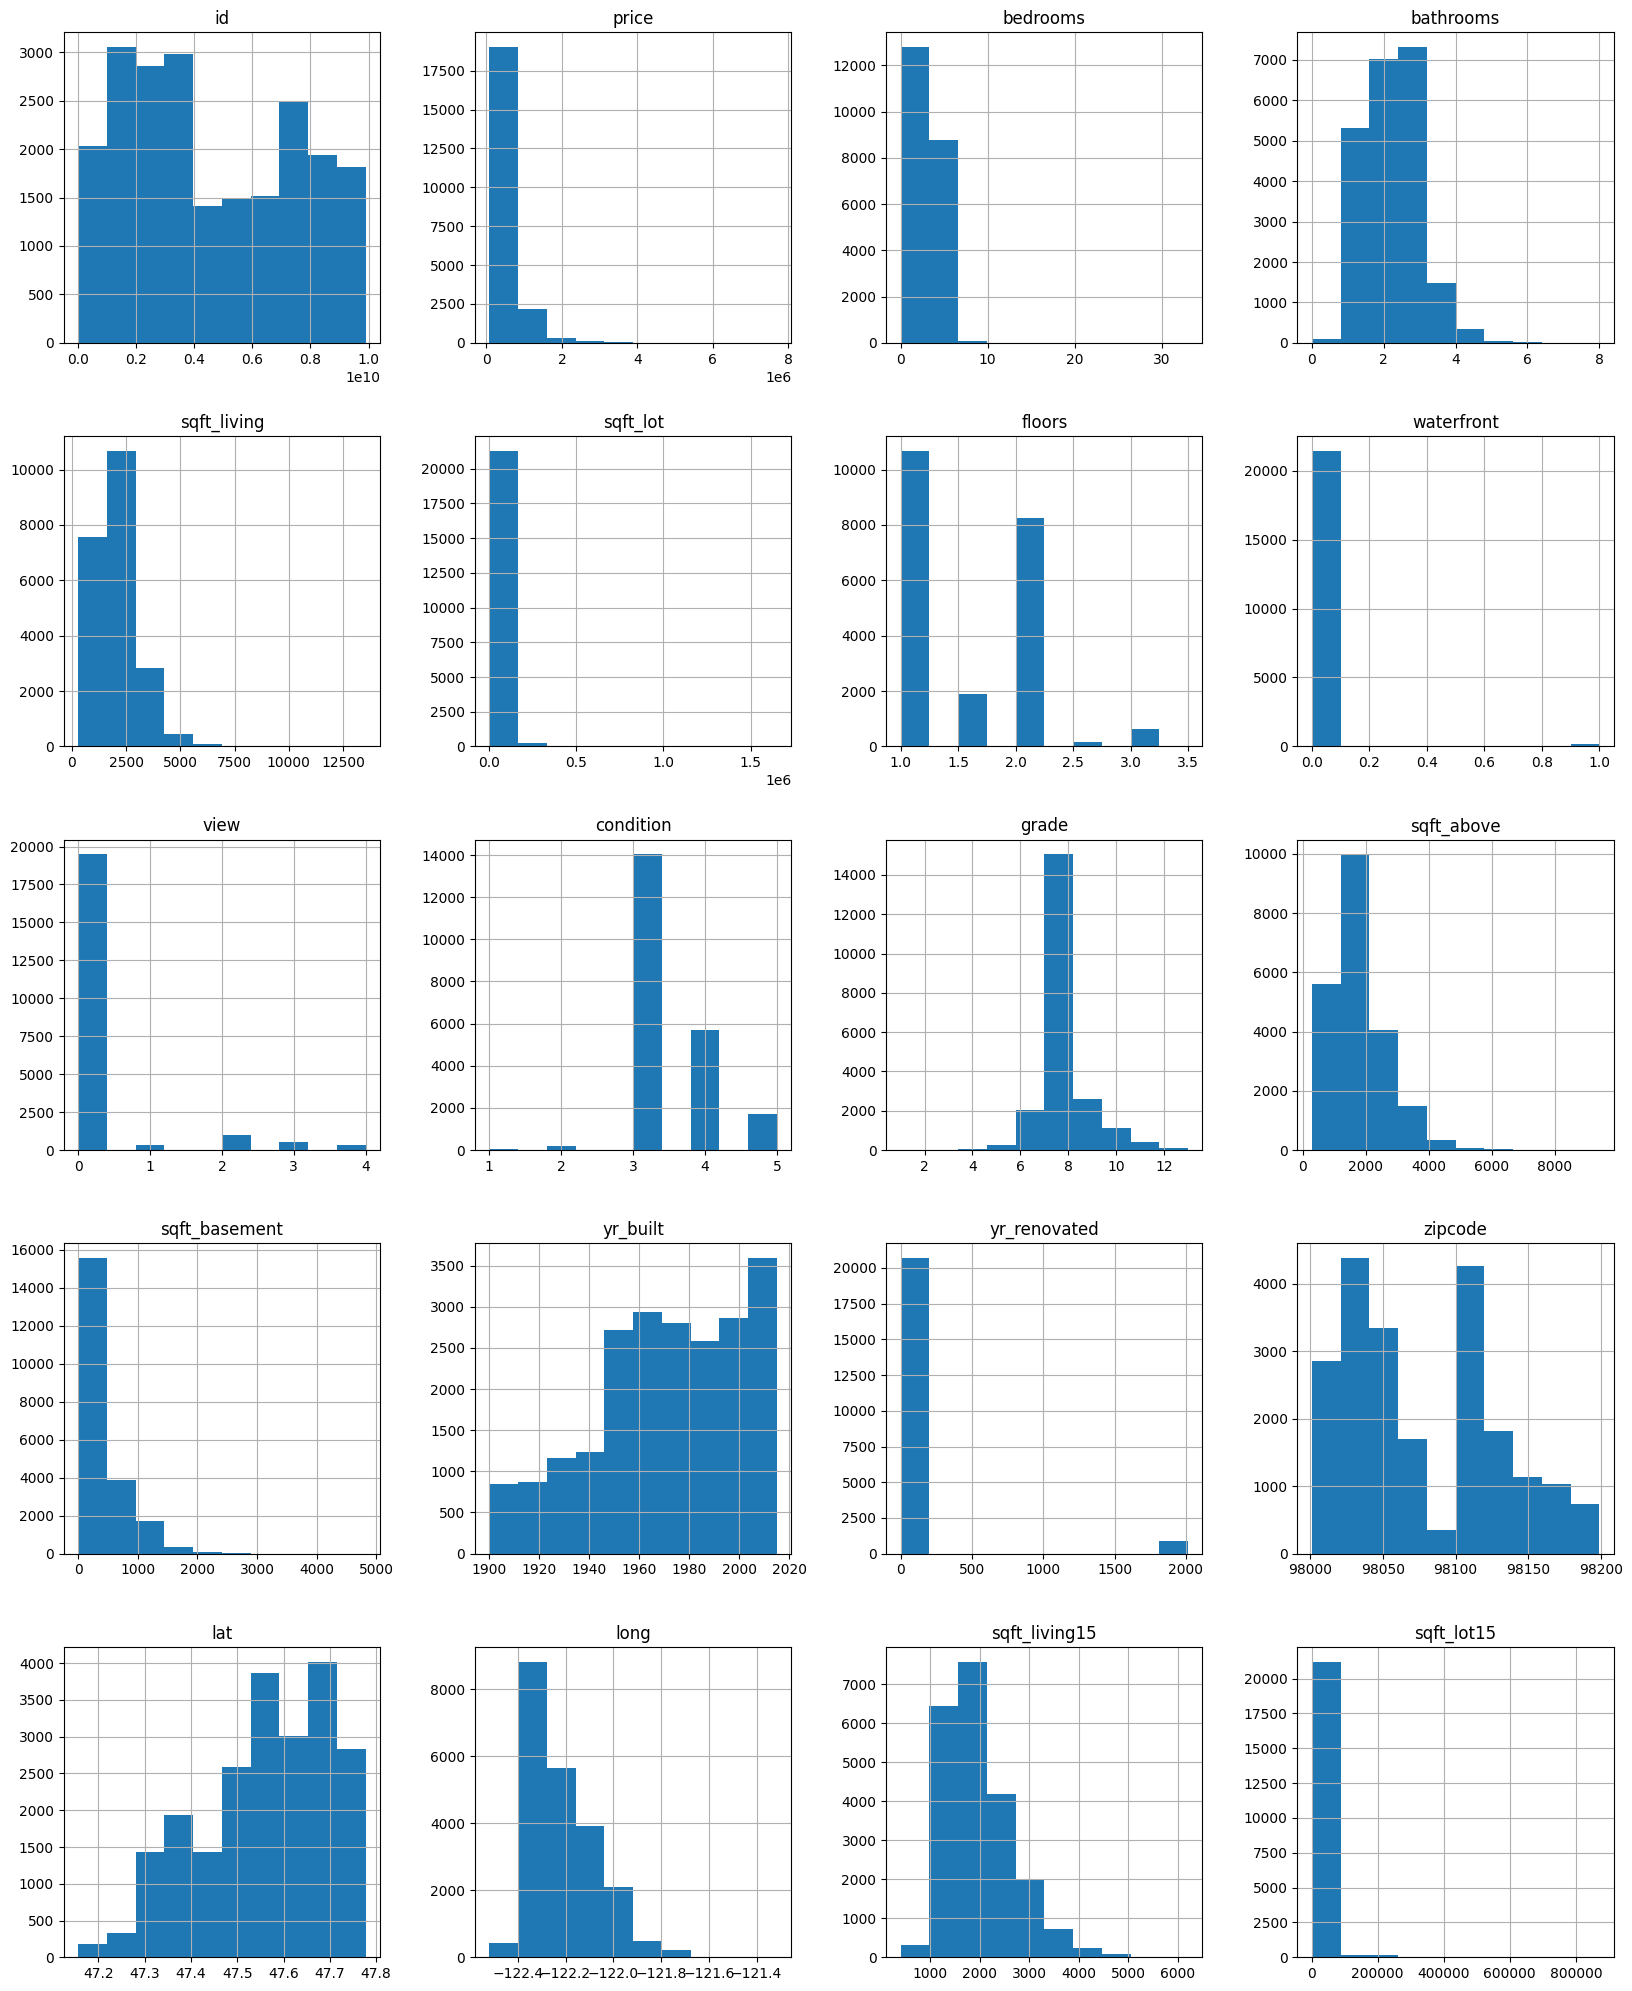

In [197]:
df.hist(figsize=(20,25))
plt.show()

In [198]:
# cek kategori attribut
df_X = df.drop(['id','date','price'],axis=1)
df_y = df[['price']]
cats = df_X.select_dtypes(include=['object', 'bool']).columns
print(cats)

Index([], dtype='object')


In [199]:
df_X = df.drop(['id', 'date', 'price'], axis=1)
df_y = df['price']

imputer = SimpleImputer(strategy='mean')
X = imputer.fit_transform(df_X)
y = df_y.astype(float).values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

reg = MLPRegressor()
reg.fit(X_train, y_train)

print('coef of determination training ', reg.score(X_train, y_train))
print('coef of determination testing ', reg.score(X_test, y_test))

print('prediction')
y_pred = reg.predict(X_test)
print(y_pred[:10])
print('real value')
print(y_test[0:10])

coef of determination training  0.5685101760158043
coef of determination testing  0.5524777073552272
prediction
[ 495624.33899646  727985.85145307 1095963.17195838 1363371.67861761
  614504.38929837  395464.05971666  628375.81391764  489382.51046448
  446438.31028754  334767.58201697]
real value
[ 365000.  865000. 1038000. 1490000.  711000.  211000.  790000.  680000.
  384500.  605000.]


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [200]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print('rmse : ', rmse)
print('r2 :', r2)

rmse :  254179.54520583586
r2 : 0.5524777073552272


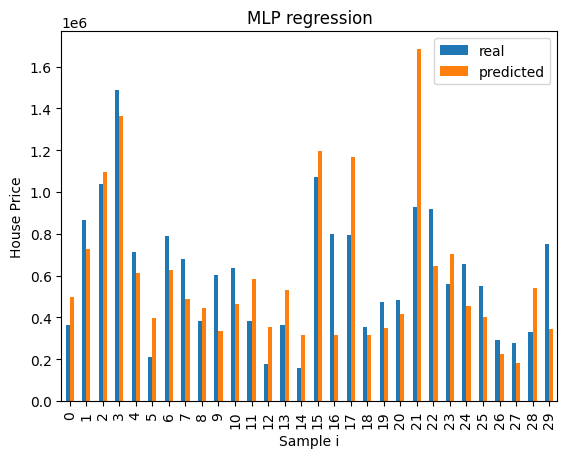

In [201]:
data1 = pd.DataFrame(y_test[:30], columns = ['real'])
data2 = pd.DataFrame(y_pred[:30], columns = ['predicted'])
df_new = pd.concat([data1, data2], axis=1)
df_new.plot(kind='bar')
plt.title("MLP regression")
plt.xlabel('Sample i')
plt.ylabel('House Price')
plt.show()

# Tugas

In [202]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from imblearn.metrics import sensitivity_specificity_support
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Klasifikasi

In [203]:
df = pd.read_csv("https://raw.githubusercontent.com/FauzanTrisuladana/content/refs/heads/master/ocupancy_dataset.csv")
df.head()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
140,2015-02-02 14:19:00,23.7000,26.272,585.200000,749.200000,0.004764,1
141,2015-02-02 14:19:59,23.7180,26.290,578.400000,760.400000,0.004773,1
142,2015-02-02 14:21:00,23.7300,26.230,572.666667,769.666667,0.004765,1
143,2015-02-02 14:22:00,23.7225,26.125,493.750000,774.750000,0.004744,1
144,2015-02-02 14:23:00,23.7540,26.200,488.600000,779.000000,0.004767,1


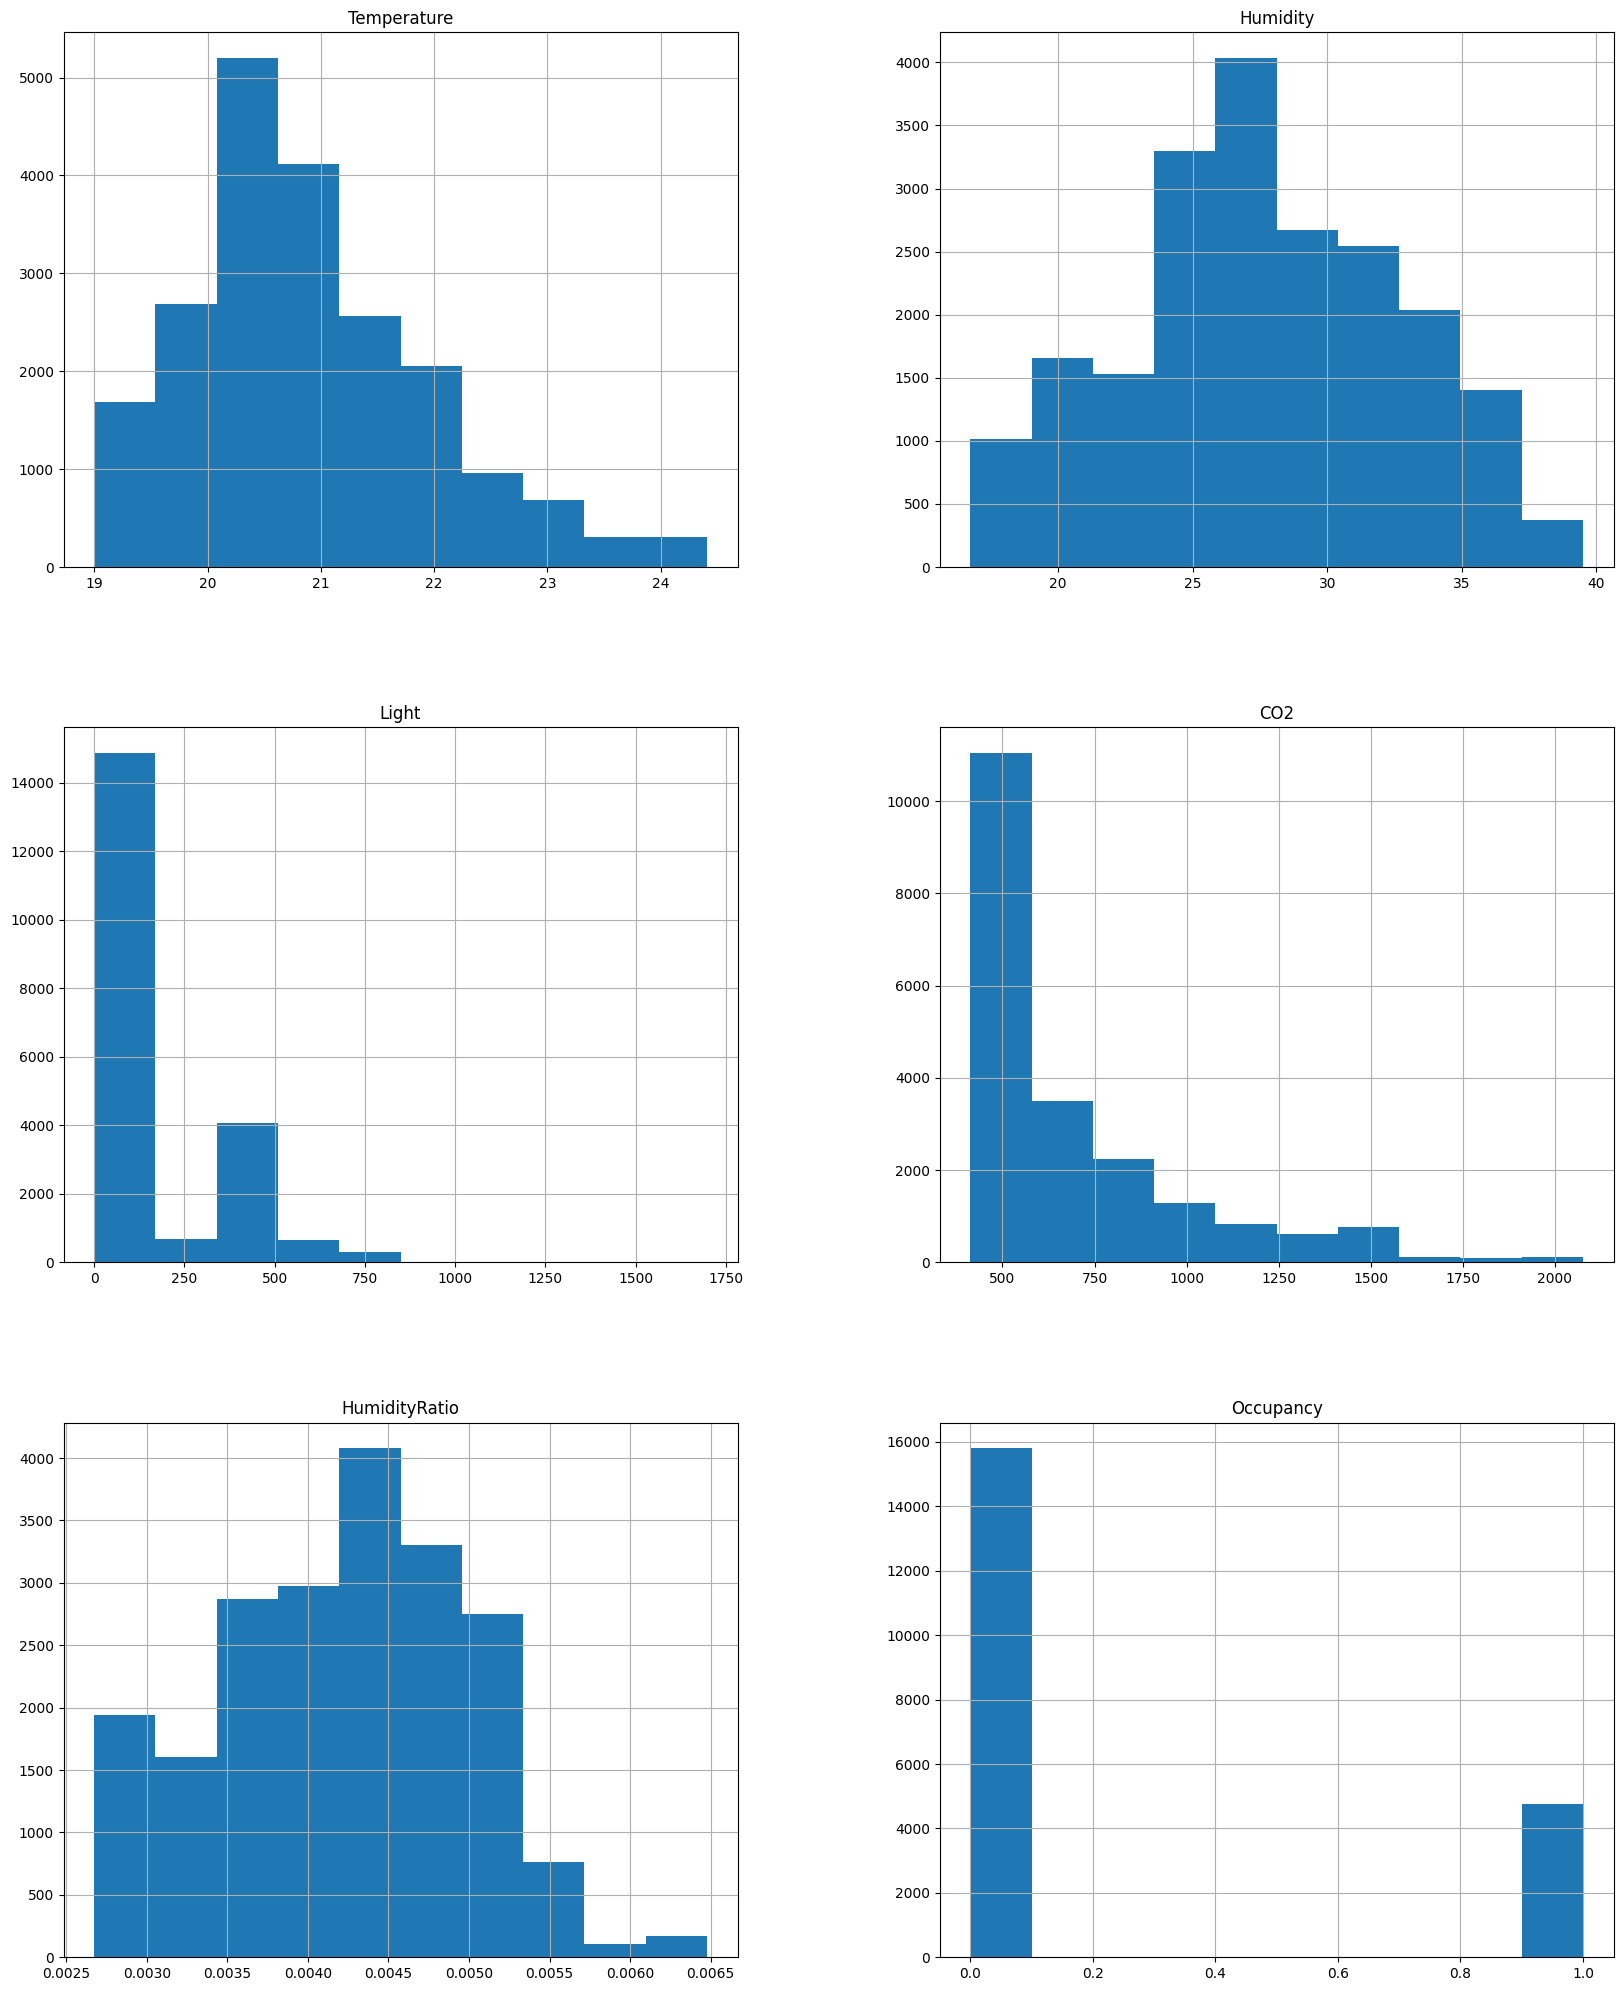

In [204]:
df.hist(figsize=(20,25))
plt.show()

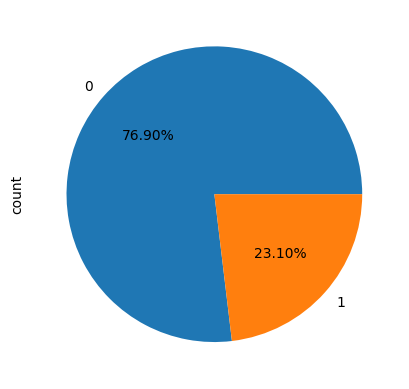

In [205]:
# cek persentase target class
data = df['Occupancy'].value_counts()
data.plot(kind='pie', autopct='%.2f%%')
plt.show()

In [206]:
df.isnull().sum()

,0
date,0
Temperature,0
Humidity,0
Light,0
CO2,0
HumidityRatio,0
Occupancy,0


In [207]:
df_X = df.drop(['date', 'Occupancy'], axis=1)
df_y = df['Occupancy']

cats = df_X.select_dtypes(include=['object', 'bool']).columns
print(cats)

Index([], dtype='object')


In [208]:
df_X

,Temperature,Humidity,Light,CO2,HumidityRatio
140,23.7000,26.2720,585.200000,749.200000,0.004764
141,23.7180,26.2900,578.400000,760.400000,0.004773
142,23.7300,26.2300,572.666667,769.666667,0.004765
143,23.7225,26.1250,493.750000,774.750000,0.004744
144,23.7540,26.2000,488.600000,779.000000,0.004767
...,...,...,...,...,...
9748,20.8150,27.7175,429.750000,1505.250000,0.004213
9749,20.8650,27.7450,423.500000,1514.500000,0.004230
9750,20.8900,27.7450,423.500000,1521.500000,0.004237
9751,20.8900,28.0225,418.750000,1632.000000,0.004279


In [209]:
# menyimpan X dan y menjadi numpy arrays
X = df_X.astype(float).values
y = df_y.astype(float)

In [210]:
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.3, random_state=8)

#scaling
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [211]:
# mulai learning
model = MLPClassifier(max_iter=500)

# model=MLPClassifier(max_iter=1000, random_state=42, activation='logistic')
model.fit(X_train, y_train)

MLPClassifier(max_iter=500)

Accuracy  0.9876783398184177
Precision  0.9549125168236877
Recall  0.9936974789915967
Confusion matrix  [[4673   67]
 [   9 1419]]


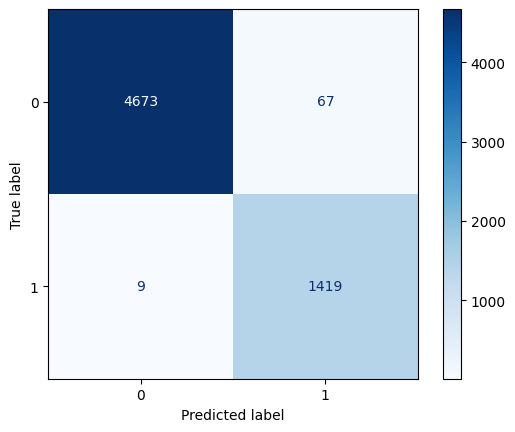

In [212]:
# visualisasi

y_pred = model.predict(X_test)
print('Accuracy ', accuracy_score(y_test, y_pred))
print('Precision ', precision_score(y_test, y_pred))
print('Recall ', recall_score(y_test, y_pred))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
disp.plot(cmap=plt.cm.Blues)
plt.show()

## Regresi

In [213]:
df = pd.read_csv("https://raw.githubusercontent.com/FauzanTrisuladana/content/refs/heads/master/Dataset%20for%20People%20for%20their%20Blood%20Glucose%20Level%20with%20their%20Superficial%20body%20feature%20readings.csv")
df.head()

,Age,Blood Glucose Level(BGL),Diastolic Blood Pressure,Systolic Blood Pressure,Heart Rate,Body Temperature,SPO2,Sweating (Y/N),Shivering (Y/N),Diabetic/NonDiabetic (D/N)
0,9,79,73,118,98,98.300707,99,0,0,N
1,9,80,73,119,102,98.300707,94,1,0,N
2,9,70,76,110,81,98.300707,98,1,0,N
3,9,70,78,115,96,98.300707,96,1,0,N
4,66,100,96,144,92,97.807052,98,0,0,N


In [214]:
df.isnull().sum()

,0
Age,0
Blood Glucose Level(BGL),0
Diastolic Blood Pressure,0
Systolic Blood Pressure,0
Heart Rate,0
Body Temperature,0
SPO2,0
Sweating (Y/N),0
Shivering (Y/N),0
Diabetic/NonDiabetic (D/N),0


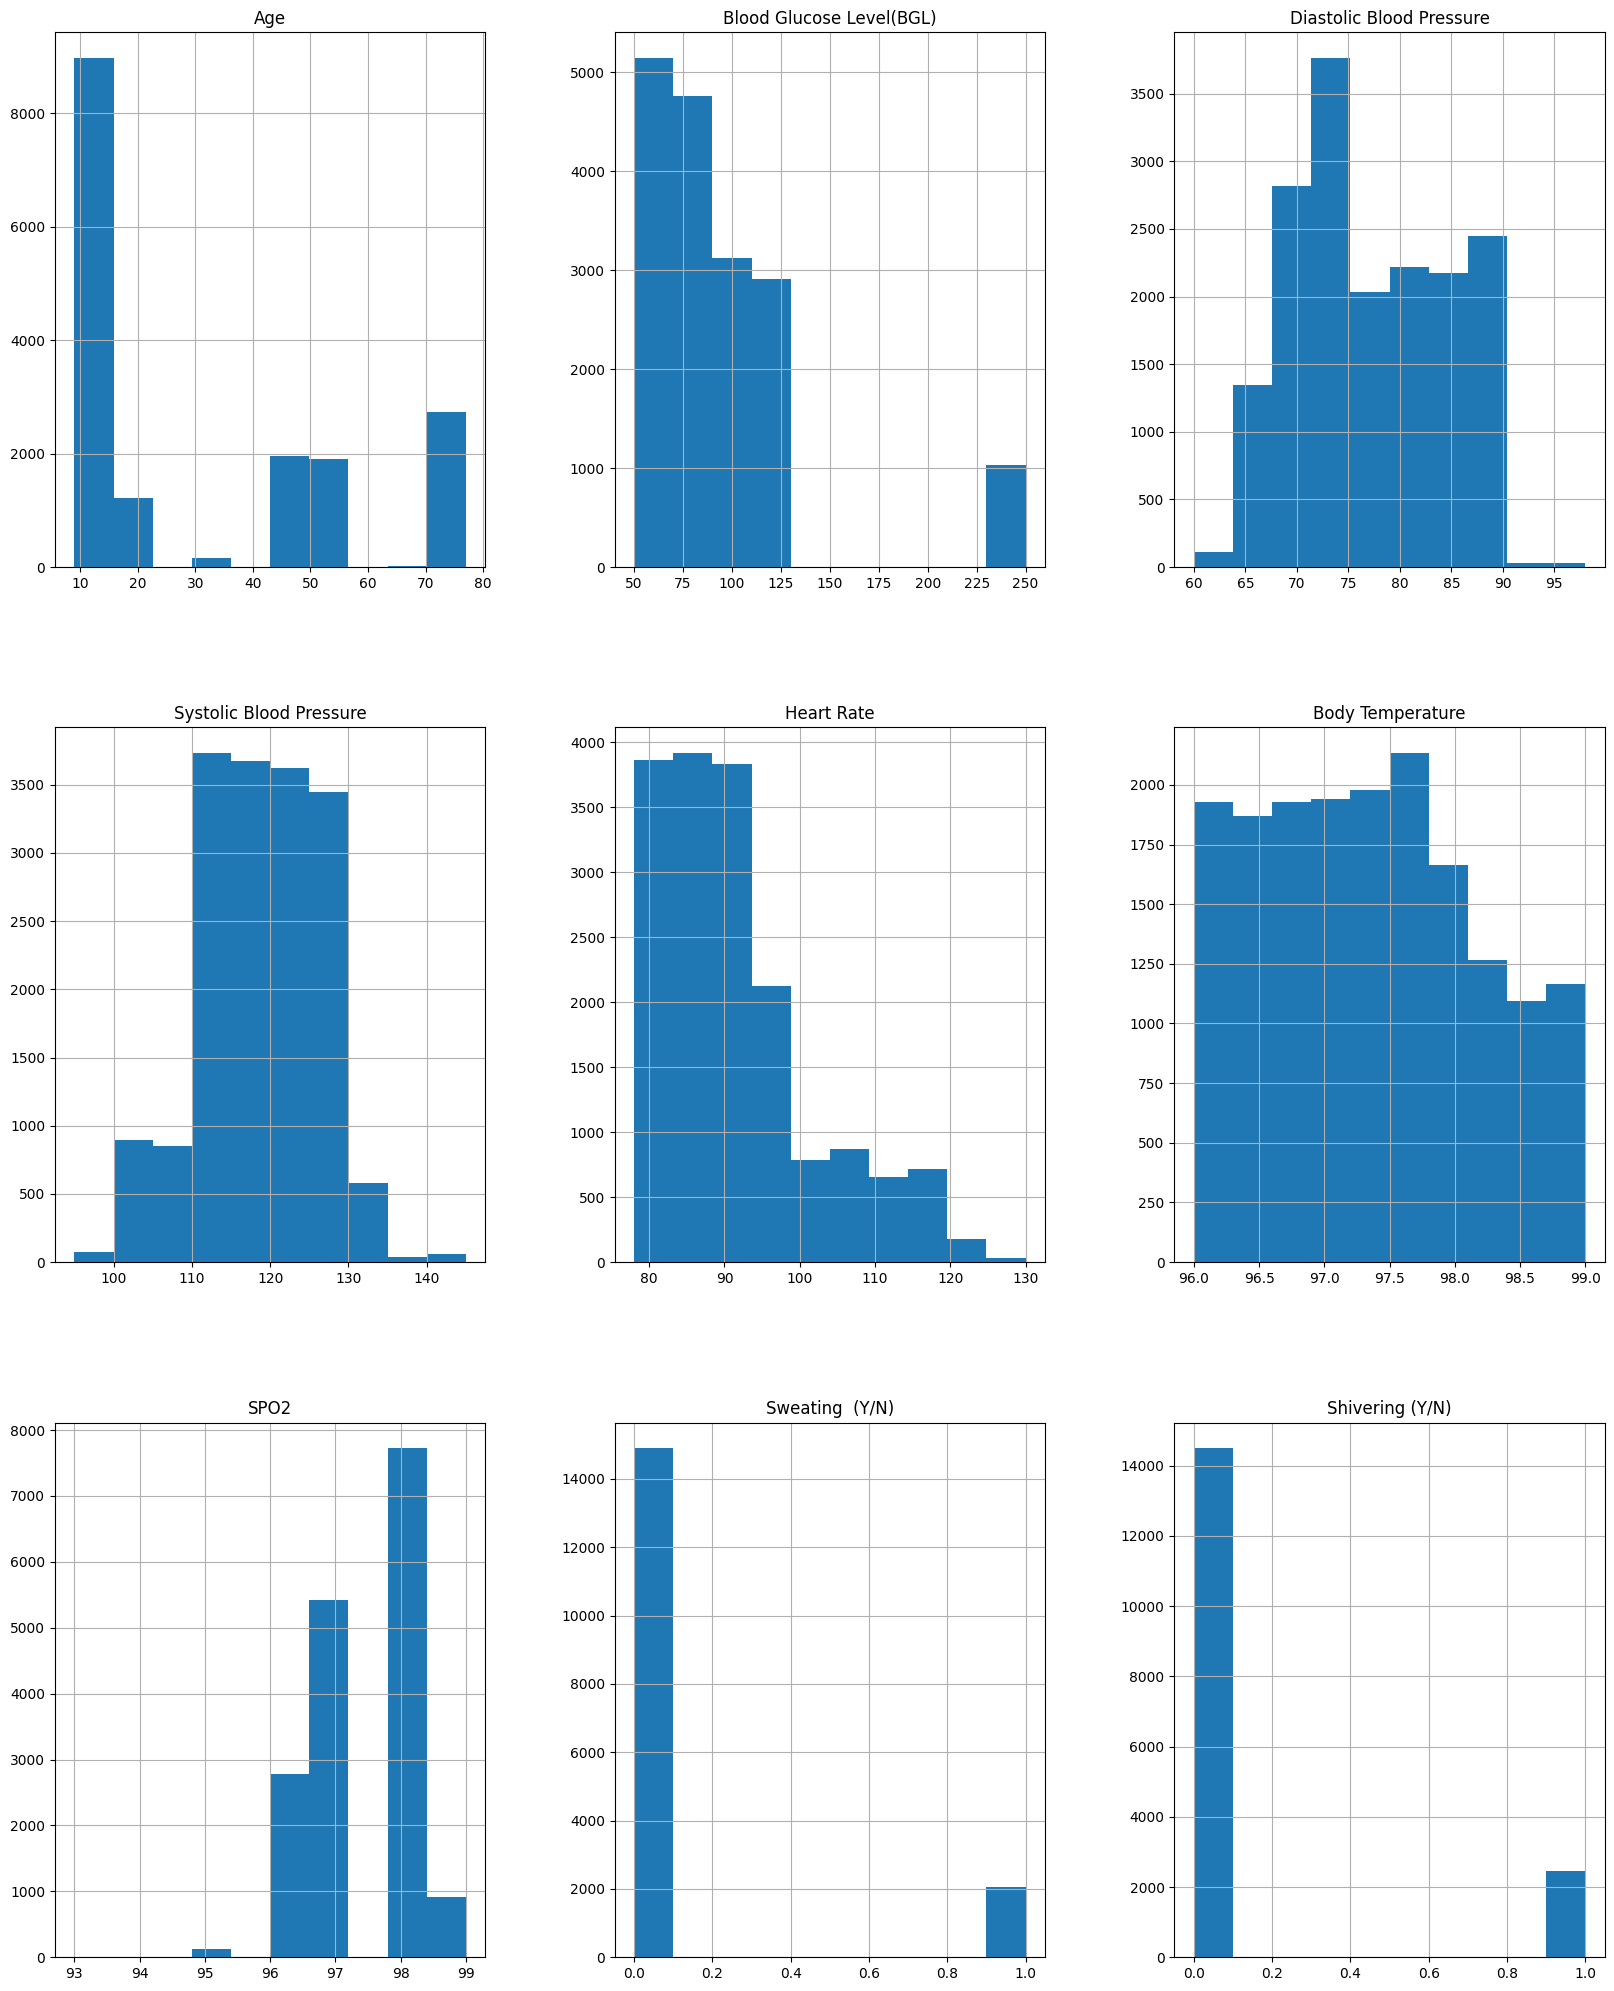

In [215]:
df.hist(figsize=(20,25))
plt.show()

In [216]:
# cek kategori attribut
df_X = df.drop(['Blood Glucose Level(BGL)'], axis=1)
df_y = df['Blood Glucose Level(BGL)']

# transform 'Diabetic/NonDiabetic (D/N)' D=1 dan N=0
df_X['Diabetic/NonDiabetic (D/N)'] = df_X['Diabetic/NonDiabetic (D/N)'].map({'D': 1, 'N': 0})

cats = df_X.select_dtypes(include=['object', 'bool']).columns
print(cats)

Index([], dtype='object')


In [217]:
imputer = SimpleImputer(strategy='mean')
X = imputer.fit_transform(df_X)
y = df_y.astype(float).values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

reg = MLPRegressor()
reg.fit(X_train, y_train)

print('coef of determination training ', reg.score(X_train, y_train))
print('coef of determination testing ', reg.score(X_test, y_test))

print('prediction')
y_pred = reg.predict(X_test)
print(y_pred[:10])
print('real value')
print(y_test[0:10])

coef of determination training  0.19229076707017712
coef of determination testing  0.1876881973419109
prediction
[109.97026162  67.38665429 104.39233657 105.66534634 109.04400747
 112.6743046   86.43376618 108.99397824 105.37040343 108.05782687]
real value
[ 79.  68. 112.  92. 106.  81.  67.  83. 104.  85.]


In [218]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print('rmse : ', rmse)
print('r2 :', r2)

rmse :  38.282653131288036
r2 : 0.1876881973419109


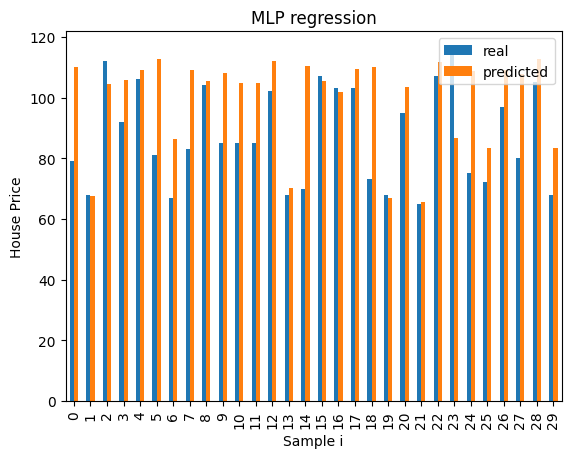

In [219]:
data1 = pd.DataFrame(y_test[:30], columns = ['real'])
data2 = pd.DataFrame(y_pred[:30], columns = ['predicted'])
df_new = pd.concat([data1, data2], axis=1)
df_new.plot(kind='bar')
plt.title("MLP regression")
plt.xlabel('Sample i')
plt.ylabel('House Price')
plt.show()